# 03 Road network: how long does it take to drive?

**Data.** Roads come from OpenStreetMap (© OpenStreetMap contributors, ODbL), downloaded with osmnx through the Overpass API. osmnx turns them into a graph: nodes are intersections, edges are road segments with their length.

**Which roads.** Only major roads are kept (OSM classes motorway, trunk, primary, secondary, tertiary and their ramps). For trips of 50-200 km, residential streets hardly change travel times but would make the network many times larger; the small error at the start and end of each trip is accepted.

**Which area.** The study area from notebook 02 (St Petersburg, Leningrad Oblast, border parts of Pskov and Novgorod oblasts), without an outer buffer, so that no trips are routed through Estonia or Finland.

**Files.** The network is saved as GraphML in `data/raw/` (not on GitHub because of its size); running this notebook recreates it.

In [1]:
import os, time
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt

RAW = "../data/raw"
PROCESSED = "../data/processed"

# Keep the osmnx download cache in data/raw (ignored by git), not in notebooks/
ox.settings.cache_folder = os.path.join(RAW, "osmnx_cache")
ox.settings.requests_timeout = 300
ox.settings.log_console = True            # print a line per downloaded piece

# Overpass mirror: on 3 Nov 2026 the main server and other mirrors refused requests (406/429)
ox.settings.overpass_url = "https://maps.mail.ru/osm/tools/overpass/api"
ox.settings.overpass_rate_limit = False   # mirrors have no status page to ask

ROAD_TYPES = "motorway|trunk|primary|secondary|tertiary"   # also matches the *_link ramps
ROAD_FILTER = f'["highway"~"{ROAD_TYPES}"]["access"!~"private|no"]'
RAW_GRAPH = os.path.join(RAW, "roads_major_raw.graphml")

In [2]:
# Study area as one polygon. The four pieces were simplified separately in 02,
# so tiny gaps can sit on shared borders: grow by 300 m and shrink back to close them
area = gpd.read_file(os.path.join(PROCESSED, "study_area.geojson")).to_crs("EPSG:32636")
polygon = area.union_all().buffer(300).buffer(-300)
polygon = gpd.GeoSeries([polygon], crs="EPSG:32636").to_crs("EPSG:4326").iloc[0]

if os.path.exists(RAW_GRAPH):
    G = ox.load_graphml(RAW_GRAPH)
else:
    t0 = time.time()
    for attempt in range(5):
        try:
            G = ox.graph_from_polygon(polygon, custom_filter=ROAD_FILTER,
                                      simplify=True, retain_all=False)
            break
        except Exception as e:
            # Finished pieces stay in the cache, so the next attempt continues from there
            wait = 60 * 2 ** attempt
            print(f"Attempt {attempt + 1} failed: {str(e)[:120]}")
            print(f"Waiting {wait // 60} min before retrying...")
            time.sleep(wait)
    else:
        raise RuntimeError("Overpass kept failing: switch overpass_url in Cell 2 and rerun")
    ox.save_graphml(G, RAW_GRAPH)
    print(f"Downloaded in {(time.time() - t0) / 60:.1f} min")

print("Nodes:", f"{G.number_of_nodes():,}", "| Edges:", f"{G.number_of_edges():,}")
print(RAW_GRAPH, round(os.path.getsize(RAW_GRAPH) / 1e6), "MB")

Nodes: 9,814 | Edges: 20,107
../data/raw\roads_major_raw.graphml 21 MB


## Speeds and travel times

Where OSM roads carry a speed limit tag (`maxspeed`), osmnx uses it. Untagged roads get a typical free-flow speed for their class (`HWY_SPEEDS`, km/h), based on Russian speed limits (90 km/h outside towns, 110 km/h on motorways) and lowered for smaller roads. Travel time per edge = length / speed. These speeds ignore traffic, so they are checked against known drive times below.

Only the largest strongly connected part of the network is kept: in it, every node can be reached from every other node respecting one-way streets, so every route can be computed.

In [3]:
# Free-flow speeds (km/h) for roads without a maxspeed tag; ramps are slower
HWY_SPEEDS = {
    "motorway": 110, "motorway_link": 60,
    "trunk": 90, "trunk_link": 50,
    "primary": 80, "primary_link": 40,
    "secondary": 70, "secondary_link": 40,
    "tertiary": 60, "tertiary_link": 30,
}
G = ox.add_edge_speeds(G, hwy_speeds=HWY_SPEEDS)
G = ox.add_edge_travel_times(G)

# Keep the largest strongly connected part (every node reachable from every other)
n_before = G.number_of_nodes()
G = ox.truncate.largest_component(G, strongly=True)
print("Nodes dropped:", n_before - G.number_of_nodes(), "of", n_before)

# Summary by road class (ramps counted with their main class)
edges = ox.graph_to_gdfs(G, nodes=False)
edges["road_class"] = edges["highway"].astype(str).str.extract(
    r"(motorway|trunk|primary|secondary|tertiary)")[0]
summary = edges.groupby("road_class").agg(
    km=("length", lambda s: round(s.sum() / 1000)),
    mean_speed=("speed_kph", "mean")).round(0)
print(summary.loc[["motorway", "trunk", "primary", "secondary", "tertiary"]])

Nodes dropped: 25 of 9814
               km  mean_speed
road_class                   
motorway      711       106.0
trunk        2614        79.0
primary      5051        66.0
secondary    9098        64.0
tertiary    12152        61.0


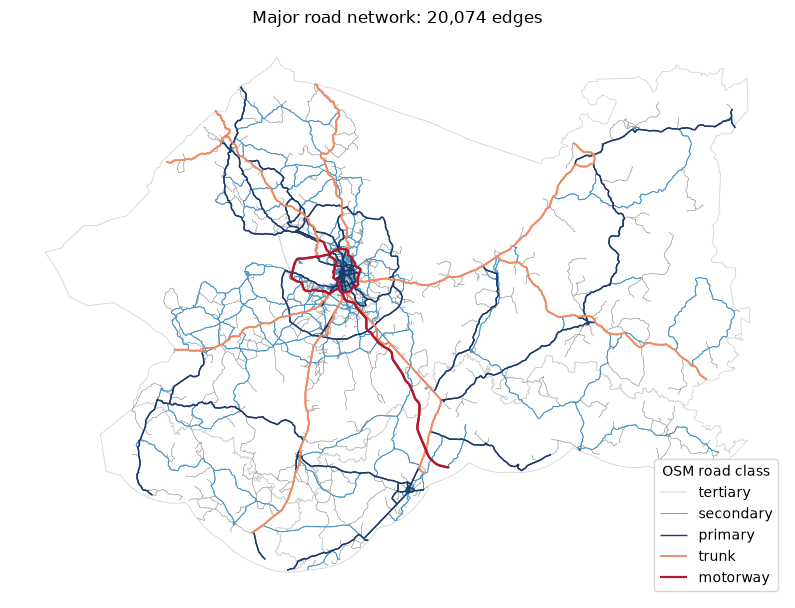

In [4]:
# Check map: roads by class, wider lines for bigger roads
STYLE = {"motorway": ("#b2182b", 1.6), "trunk": ("#ef8a62", 1.3), "primary": ("#1b3a6b", 1.0),
         "secondary": ("#4393c3", 0.6), "tertiary": ("#999999", 0.3)}

fig, ax = plt.subplots(figsize=(10, 8))
area.boundary.plot(ax=ax, color="lightgrey", linewidth=0.6)
edges_m = edges.to_crs("EPSG:32636")
for cls in ["tertiary", "secondary", "primary", "trunk", "motorway"]:   # big roads on top
    color, width = STYLE[cls]
    edges_m[edges_m["road_class"] == cls].plot(ax=ax, color=color, linewidth=width, label=cls)
ax.legend(loc="lower right", title="OSM road class")
ax.set_title(f"Major road network: {G.number_of_edges():,} edges")
ax.set_axis_off()
plt.show()

## Checking drive times

Model times were compared with Yandex Maps (fastest route; St Petersburg routes with departure on Saturday 10:00, the typical start of a day trip). Rural routes match within 2 minutes (Kingisepp to Slantsy, Slantsy to Gdov), and route lengths agree within a few percent, so the network and the rural speeds are right. Every route starting in St Petersburg was about 40-45 minutes too fast, almost independent of trip length: the time is lost while getting out of the city and its suburbs (traffic lights, congestion), not along the road.

**Fix.** A slow zone covers St Petersburg plus a `SLOW_BUFFER_KM` belt of suburbs. Travel times on all roads in the zone except motorways (KAD ring road, WHSD, M-11) are multiplied by one factor. Because slower streets change which route is fastest, the factor is chosen by trying values and recomputing the routes each time; the value with the smallest error on the three St Petersburg routes is kept. Free-flow times are kept in `travel_time_ff`. Traffic varies by day and hour, so this is an average weekend-morning correction.

In [5]:
# Sanity check: model drive times vs Yandex Maps (fastest route)
import pandas as pd

PLACES = {
    "SPb (Palace Square)": (59.9391, 30.3158),
    "Slantsy": (59.118, 28.088),
    "Kingisepp": (59.373, 28.613),
    "Ivangorod": (59.373, 28.212),
    "Staraya Ladoga": (60.000, 32.296),
    "Gdov": (58.744, 27.816),
}
# Yandex minutes: SPb routes departing Sat 7 Nov 2026 10:00; rural routes checked 5 Nov 2026
ROUTES = [
    ("SPb (Palace Square)", "Slantsy", 187),
    ("SPb (Palace Square)", "Ivangorod", 161),
    ("SPb (Palace Square)", "Staraya Ladoga", 133),
    ("Kingisepp", "Slantsy", 48),
    ("Slantsy", "Gdov", 38),
]
SLOW_BUFFER_KM = 15   # slow zone = St Petersburg + this belt of suburbs

# Mark slow-zone edges: both ends in the zone, not a motorway (KAD, WHSD, M-11 stay fast)
spb = area.loc[area["region"] == "Saint Petersburg", "geometry"].iloc[0]      # area is in metres
zone = gpd.GeoSeries([spb.buffer(SLOW_BUFFER_KM * 1000)], crs="EPSG:32636").to_crs("EPSG:4326").iloc[0]
node_pts = ox.graph_to_gdfs(G, edges=False)
in_zone = set(node_pts.index[node_pts.within(zone)])
for u, v, k, d in G.edges(keys=True, data=True):
    d["slow_zone"] = (u in in_zone) and (v in in_zone) and ("motorway" not in str(d["highway"]))
    d.setdefault("travel_time_ff", d["travel_time"])      # keep free-flow time once

nodes = {name: ox.distance.nearest_nodes(G, X=lon, Y=lat) for name, (lat, lon) in PLACES.items()}

def set_factor(f):
    # travel time = free-flow time, multiplied by f inside the slow zone
    for u, v, k, d in G.edges(keys=True, data=True):
        d["travel_time"] = d["travel_time_ff"] * (f if d["slow_zone"] else 1)

def check_routes():
    rows = []
    for a, b, ref in ROUTES:
        path = ox.routing.shortest_path(G, nodes[a], nodes[b], weight="travel_time")
        route = ox.routing.route_to_gdf(G, path, weight="travel_time")
        rows.append({"route": f"{a} -> {b}",
                     "model_min": route["travel_time"].sum() / 60,
                     "zone_min": route.loc[route["slow_zone"], "travel_time"].sum() / 60,
                     "model_km": route["length"].sum() / 1000,
                     "yandex_min": ref})
    out = pd.DataFrame(rows)
    out["gap_min"] = out["yandex_min"] - out["model_min"]
    return out

set_factor(1)
before = check_routes()
print(before.round(0))

                                   route  model_min  zone_min  model_km  \
0         SPb (Palace Square) -> Slantsy      145.0      31.0     182.0   
1       SPb (Palace Square) -> Ivangorod      116.0      31.0     151.0   
2  SPb (Palace Square) -> Staraya Ladoga       92.0      26.0     123.0   
3                   Kingisepp -> Slantsy       46.0       0.0      54.0   
4                        Slantsy -> Gdov       37.0       0.0      44.0   

   yandex_min  gap_min  
0         187     42.0  
1         161     45.0  
2         133     41.0  
3          48      2.0  
4          38      1.0  


In [6]:
# Try slowdown factors; routes are recomputed each time, because they change as the zone gets slower
spb_routes = before["route"].str.startswith("SPb")
results = []
for f in [1 + 0.25 * i for i in range(17)]:          # 1.0 to 5.0
    set_factor(f)
    gaps = check_routes().loc[spb_routes, "gap_min"]
    results.append({"factor": f, "mean_gap_min": gaps.mean(), "rmse_min": (gaps ** 2).mean() ** 0.5})
results = pd.DataFrame(results)
print(results.round(1).to_string(index=False))

# Keep the best factor and show the final check
SLOW_FACTOR = results.loc[results["rmse_min"].idxmin(), "factor"]
set_factor(SLOW_FACTOR)
after = check_routes()
after["diff_pct"] = after["model_min"] / after["yandex_min"] * 100 - 100
print(f"\nChosen factor: {SLOW_FACTOR}")
print(after.round(0))

 factor  mean_gap_min  rmse_min
    1.0          42.7      42.7
    1.2          35.9      35.9
    1.5          30.2      30.3
    1.8          24.5      24.6
    2.0          18.8      19.0
    2.2          13.2      13.6
    2.5           8.1       8.9
    2.8           3.2       4.8
    3.0          -1.6       3.8
    3.2          -6.5       7.3
    3.5         -11.3      11.8
    3.8         -16.2      16.5
    4.0         -21.0      21.2
    4.2         -25.9      26.1
    4.5         -30.8      30.9
    4.8         -35.6      35.7
    5.0         -40.2      40.3

Chosen factor: 3.0
                                   route  model_min  zone_min  model_km  \
0         SPb (Palace Square) -> Slantsy      188.0      59.0     190.0   
1       SPb (Palace Square) -> Ivangorod      159.0      59.0     160.0   
2  SPb (Palace Square) -> Staraya Ladoga      139.0      56.0     145.0   
3                   Kingisepp -> Slantsy       46.0       0.0      54.0   
4                        Slan

In [7]:
# Save the network with speeds and travel times for notebook 04 (data/raw, not on GitHub)
ROADS_GRAPH = os.path.join(RAW, "roads_drive.graphml")
ox.save_graphml(G, ROADS_GRAPH)
print(ROADS_GRAPH, round(os.path.getsize(ROADS_GRAPH) / 1e6), "MB")

../data/raw\roads_drive.graphml 24 MB
